# Saudi Dialect 4-Class Dataset: Semi-Supervised Labeling Pipeline

**Classes:** Positive · Negative · Neutral · Ironic

**What this notebook does**
1. Loads the three datasets (Sa'7r, Telecom, Bank), cleans and merges them, and **describes** the result.
2. Draws a **balanced sample** for you to label by hand (and a smaller one for a second annotator).
3. Fine-tunes a labeler model on **your manual labels only**, with a TF-IDF baseline for comparison.
4. Labels the remaining rows. Predictions with confidence **>= threshold** become pseudo-labels, the rest stay **unlabeled**.
5. Exports everything as CSV files (zipped).

**Rules this notebook enforces (for the paper)**
- The dev and test sets are 100% manual and never pseudo-labeled. Final results are reported on the manual test set only.
- Fixed random seed everywhere.
- Original dataset labels are hidden from you while labeling, to avoid anchoring.

**Run order:** run the cells top to bottom. There are two pauses where you work outside the notebook (manual labeling).

In [ ]:
!pip install -q "transformers>=4.46,<5" "datasets>=2.19" accelerate scikit-learn pandas openpyxl matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import os, re, json, random, zipfile, warnings, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, cohen_kappa_score
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:
    display = print

SEED = 42
def set_all_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_all_seeds()
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("WARNING: no GPU. In Colab: Runtime > Change runtime type > T4 GPU")

Device: cuda


## 1. Configuration
Edit this cell only. Put the exact **file name** of each dataset and the **column names** that hold the text and the original label.
If a dataset has no label column, set `"label_col": None`.

> **Bias note:** `LABELER_MODEL` is AraBERT as you requested. Because AraBERT is also one of the models you plan to compare, either state this as a limitation in the paper or switch the labeler to a model you do not compare (for example CAMeLBERT; check the exact name on huggingface.co).

In [ ]:
DATASETS = {
    "Sa7r":    {"path": "sa7r.csv",    "text_col": "Tweets with Decoded emojis", "label_col": "Final Annotation"},
    "Telecom": {"path": "telecom.csv", "text_col": " Tweet", "label_col": " Label"},
    "Bank":    {"path": "bank.csv",    "text_col": "Tweet", "label_col": "Final annotation"},
}

LABELS = ["Positive", "Negative", "Neutral", "Ironic"]

N_MANUAL           = 1200   # rows you will label by hand
N_SECOND_ANNOTATOR = 200    # subset a second person labels (for Cohen's kappa)
MIN_WORDS          = 2      # drop texts shorter than this
THRESHOLD          = 0.90   # pseudo-label confidence threshold

LABELER_MODEL = "aubmindlab/bert-base-arabertv02-twitter"
MAX_LEN, LR, BATCH, EPOCHS, PATIENCE = 128, 2e-5, 16, 4, 2

LABELED_FILE   = "labeled.csv"              # your manual labels (filled to_label.csv)
LABELED_FILE_2 = "labeled_annotator2.csv"   # optional second annotator
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

results = {"seed": SEED, "threshold": THRESHOLD, "labeler_model": LABELER_MODEL,
           "n_manual_requested": N_MANUAL}

## 2. Load, clean, merge, describe
Upload your three files when asked (or place them in the Colab file panel / mount Drive and edit the paths above).

In [ ]:
def ensure_files(names):
    missing = [n for n in names if not os.path.exists(n)]
    if missing:
        try:
            from google.colab import files
            print("Please upload:", missing)
            files.upload()
        except ImportError:
            raise FileNotFoundError(f"Missing files: {missing}")

def download(path):
    try:
        from google.colab import files
        files.download(path)
    except Exception:
        print("Saved at:", path)

def read_any(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in (".csv", ".tsv"):
        for sep in (",", "\t", ";"):
            for enc in ("utf-8-sig", "utf-8", "windows-1256", "cp1256", "iso-8859-6"):
                try:
                    return pd.read_csv(path, sep=sep, encoding=enc)
                except Exception:
                    try:
                        return pd.read_csv(path, sep=sep, encoding=enc, on_bad_lines='skip')
                    except Exception:
                        continue
        try:
            # Try guessing separator using python engine
            for enc in ("utf-8-sig", "utf-8", "windows-1256", "cp1256", "iso-8859-6"):
                try:
                    return pd.read_csv(path, sep=None, engine='python', encoding=enc)
                except Exception:
                    continue
        except Exception:
            pass

        # Fallback: Maybe it is actually an Excel file with a .csv extension
        try:
            return pd.read_excel(path)
        except Exception:
            raise ValueError(f"Could not decode or parse {path}")

    if ext in (".xlsx", ".xls"):
        try:
            return pd.read_excel(path)
        except Exception:
            # Maybe it is actually a CSV with an .xlsx extension
            try:
                return pd.read_csv(path, sep=None, engine='python', encoding='utf-8-sig')
            except Exception:
                raise ValueError(f"Could not decode or parse {path}")
    if ext == ".json":
        return pd.read_json(path)
    if ext == ".jsonl":
        return pd.read_json(path, lines=True)
    raise ValueError(f"Unsupported file type: {ext}")

ensure_files([c["path"] for c in DATASETS.values()])

raw = {}
for name, cfg in DATASETS.items():
    df = read_any(cfg["path"])
    raw[name] = df
    print(f"\n=== {name}: {df.shape[0]:,} rows | columns = {list(df.columns)}")
    assert cfg["text_col"], f"{name}: text_col is empty."
    assert cfg["text_col"] in df.columns, f"{name}: text_col '{cfg['text_col']}' not found. Fix DATASETS above. Available: {list(df.columns)}"
    if cfg.get("label_col"):
        assert cfg["label_col"] in df.columns, f"{name}: label_col '{cfg['label_col']}' not found. Fix DATASETS above. Available: {list(df.columns)}"
    display(df.head(3))

Please upload: ['sa7r.csv', 'telecom.csv', 'bank.csv']


Saving telecom.csv to telecom.csv
Saving bank.csv to bank.csv
Saving sa7r.csv to sa7r.csv

=== Sa7r: 19,804 rows | columns = ['Tweet ID', 'Tweets with Decoded emojis', 'Final Annotation']


,Tweet ID,Tweets with Decoded emojis,Final Annotation
0,1,نعم من علامات الجمال تلك الطيبه التي لاترى بل ...,ليست تهكم
1,2,المعرفه الجديده والمهارات الجديده واعتماد طرائ...,ليست تهكم
2,3,لايشيخ,تهكم



=== Telecom: 20,000 rows | columns = [' Tweet', ' Label', 'Company']


,Tweet,Label,Company
0,@STC1100 الله لاينهكم شركة STC ركبو لنا اليا...,Positive,STC
1,@alrakoo @mmshibani @GOclub @STC_KSA @ZainKSA...,Positive,STC
2,اعلان توعوي مميز من شركة STC,Positive,STC



=== Bank: 12,048 rows | columns = ['Tweet', 'Bank', 'Tokens', 'Tokens without stop words', 'Annotator 1 & 3', 'Annotator 2 & 4', 'Final annotation']


,Tweet,Bank,Tokens,Tokens without stop words,Annotator 1 & 3,Annotator 2 & 4,Final annotation
0,الله يقلعك من بنك دمر مستقبلنا الله حسبنا الله...,SAIB,"['الله', 'يقلعك', 'من', 'بنك', 'دمر', 'مستقبلن...","['الله', 'يقلعك', 'بنك', 'دمر', 'مستقبلنا', 'ا...",NEG,NEG,NEG
1,صار لي يومين بحاول اوصل لاي شخص من قبلكم يرد ع...,SAIB,"['صار', 'لي', 'يومين', 'بحاول', 'اوصل', 'لاي',...","['صار', 'لي', 'يومين', 'بحاول', 'اوصل', 'لاي',...",NEG,NEG,NEG
2,صادق كثير من الزملاء يشتكون منه الصراحه وبصراح...,SAIB,"['صادق', 'كثير', 'من', 'الزملاء', 'يشتكون', 'م...","['صادق', 'كثير', 'الزملاء', 'يشتكون', 'منه', '...",NEG,NEG,NEG


In [ ]:
AR_DIAC  = re.compile(r"[\u064B-\u0652\u0670\u0640]")   # tashkeel + tatweel
URL      = re.compile(r"(https?://\S+|www\.\S+)")
MENTION  = re.compile(r"@\w+")
REPEAT   = re.compile(r"(.)\1{2,}")                      # 3+ repeated chars -> 2
HAS_AR   = re.compile(r"[\u0600-\u06FF]")

def clean_text(t):
    t = str(t)
    t = URL.sub(" ", t)
    t = MENTION.sub(" ", t)
    t = re.sub(r"\bRT\b", " ", t)
    t = t.replace("#", " ").replace("_", " ")
    t = AR_DIAC.sub("", t)
    t = REPEAT.sub(r"\1\1", t)
    return re.sub(r"\s+", " ", t).strip()
# Note: emojis and dialect letter forms are kept on purpose (useful signals for irony).

def build_clean(raw):
    frames, log = [], []
    for name, cfg in DATASETS.items():
        df = raw[name]
        lab = df[cfg["label_col"]].astype(str) if cfg.get("label_col") else pd.Series("none", index=df.index)
        d = pd.DataFrame({"source": name, "text_raw": df[cfg["text_col"]], "orig_label": lab})
        n = {"source": name, "raw_rows": len(d)}
        d = d.dropna(subset=["text_raw"]);                           n["after_drop_empty"] = len(d)
        d["text"] = d["text_raw"].astype(str).map(clean_text)
        d = d[d["text"].str.contains(HAS_AR)];                       n["after_non_arabic_removed"] = len(d)
        d = d[d["text"].str.split().str.len() >= MIN_WORDS];         n["after_min_words"] = len(d)
        d = d.drop_duplicates(subset="text");                        n["after_dedup_in_source"] = len(d)
        frames.append(d); log.append(n)
    merged = pd.concat(frames, ignore_index=True)
    before = len(merged)
    merged = merged.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
    print(f"Cross-source duplicates removed: {before - len(merged):,}")
    merged.insert(0, "id", np.arange(len(merged)))
    return merged, pd.DataFrame(log)

merged, cleaning_log = build_clean(raw)
cleaning_log.to_csv(f"{OUT_DIR}/cleaning_log.csv", index=False)
merged.to_csv(f"{OUT_DIR}/merged_clean.csv", index=False, encoding="utf-8-sig")
print("Cleaning log (use it for the Dataset section of the paper):")
display(cleaning_log)
print("Merged clean dataset:", merged.shape)

Cross-source duplicates removed: 6
Cleaning log (use it for the Dataset section of the paper):


,source,raw_rows,after_drop_empty,after_non_arabic_removed,after_min_words,after_dedup_in_source
0,Sa7r,19804,19635,19630,19603,19422
1,Telecom,20000,20000,20000,19522,9444
2,Bank,12048,12048,12048,12047,12022


Merged clean dataset: (40882, 5)


Dataset description by source:


,rows,mean_words,median_words,min_words,max_words
source,,,,,
Bank,12018.0,18.0,14.0,2.0,60.0
Sa7r,19422.0,14.8,11.0,2.0,86.0
Telecom,9442.0,12.7,12.0,2.0,31.0
TOTAL,40882.0,15.3,12.0,2.0,86.0



Original labels per source (these are NOT the 4 target classes):


orig_label,\r\nليست تهكم,NEG,NEU,Negative,POS,Positive,تهكم,تهكم\r\n,ليست تهكم
source,,,,,,,,,
Bank,0,8657,1235,0,2126,0,0,0,0
Sa7r,1,0,0,0,0,0,7963,26,11432
Telecom,0,0,0,8378,0,1064,0,0,0


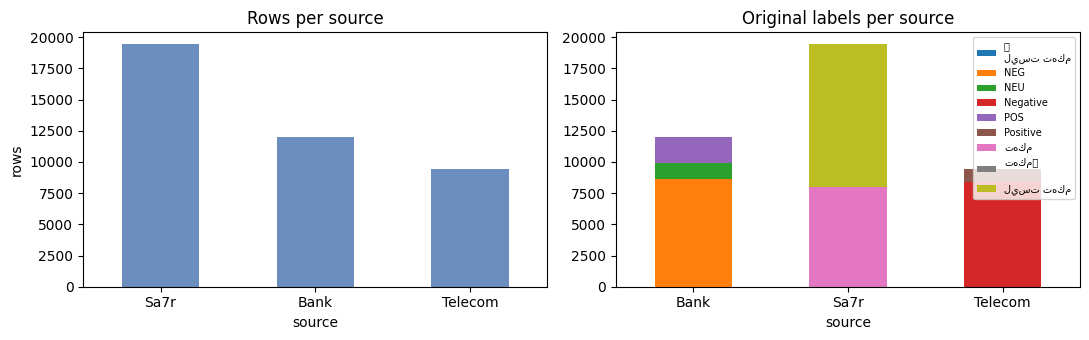


Random examples:
--- Sa7r
  • الحمدلله والشكر والمته الله يشفيها ويعافيها يارب ويحفظكم
  • ماطاح الا اسمي سوبهان الله
  • اخاف اني اتطنز وتنرد لي بس وحده بااستراحه العيد حقت القبيله قبل:basketball::basketball:ونا ترضع ولدها وجت بنتها سرقت جوالها وانحاشت وركضت ال
--- Telecom
  • شركة لاتوجد فيها مصداقيه ويسحبون رصيدك مع اني عميل ذهبي وعميل صار لي معهم اكثر من 7 سنوات
  • السلام عليكم ورحمه الله ✋🏼✋🏼✋🏼الساده شركة زين انا الان في دولة مصر والجوال مايشتغل امل المساعده
  • ياخي شوفولكم حل مع الشبكة لها 3 ايام بطيئة جدا
--- Bank
  • توني طالع من بنك الانماء ابن الكلب نصيحه رح لراجحي يارجال
  • السلام عليكم عندي مشكله ممكن تردون بالخاص
  • لنا اسبوعين عشان نسوي احلال سياره وكل يوم يقولون فيه ورقه ناقصه والهاتف المصرفي مايرد


In [ ]:
merged["n_words"] = merged["text"].str.split().str.len()

summary = merged.groupby("source").agg(
    rows=("id", "count"), mean_words=("n_words", "mean"), median_words=("n_words", "median"),
    min_words=("n_words", "min"), max_words=("n_words", "max")).round(1)
summary.loc["TOTAL"] = [len(merged), merged.n_words.mean().round(1), merged.n_words.median(),
                        merged.n_words.min(), merged.n_words.max()]
print("Dataset description by source:")
display(summary)

print("\nOriginal labels per source (these are NOT the 4 target classes):")
orig_ct = pd.crosstab(merged["source"], merged["orig_label"])
display(orig_ct)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
merged["source"].value_counts().plot.bar(ax=ax[0], color="#6c8ebf", rot=0)
ax[0].set_title("Rows per source"); ax[0].set_ylabel("rows")
orig_ct.plot.bar(stacked=True, ax=ax[1], rot=0)
ax[1].set_title("Original labels per source"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_dataset_description.png", dpi=200); plt.show()

print("\nRandom examples:")
for s in merged.source.unique():
    print(f"--- {s}")
    for t in merged[merged.source == s].sample(3, random_state=SEED).text:
        print("  •", t[:140])

results["merged_rows"] = int(len(merged))
results["rows_per_source"] = merged["source"].value_counts().to_dict()

## 3. Draw the sample you will label by hand
The sample is stratified by (source, original label) so every source and every original label is represented.
Two files are produced for you to download:
- `to_label.csv`: **you** fill the `label` column.
- `to_label_annotator2.csv`: a subset for a **second person** (used for Cohen's kappa).

The original labels are saved separately in `sample_meta_hidden.csv`. **Do not open it while labeling.**

In [ ]:
def stratified_sample(df, n, seed):
    groups = [g for _, g in df.groupby(["source", "orig_label"])]
    quota = max(1, n // len(groups))
    s = pd.concat([g.sample(n=min(quota, len(g)), random_state=seed) for g in groups])
    if len(s) < n:                                   # top up randomly
        rest = df.drop(s.index)
        s = pd.concat([s, rest.sample(n=min(n - len(s), len(rest)), random_state=seed)])
    return s.sample(frac=1, random_state=seed)       # shuffle

sample = stratified_sample(merged, N_MANUAL, SEED)
second = sample.sample(n=min(N_SECOND_ANNOTATOR, len(sample)), random_state=SEED)

f1_, f2_, fm_ = f"{OUT_DIR}/to_label.csv", f"{OUT_DIR}/to_label_annotator2.csv", f"{OUT_DIR}/sample_meta_hidden.csv"
sample[["id", "text"]].assign(label="").to_csv(f1_, index=False, encoding="utf-8-sig")
second[["id", "text"]].assign(label="").to_csv(f2_, index=False, encoding="utf-8-sig")
sample[["id", "source", "orig_label"]].to_csv(fm_, index=False, encoding="utf-8-sig")

print(f"Sample to label: {len(sample):,} rows | second annotator: {len(second):,} rows")
display(sample.source.value_counts().to_frame("rows_in_sample"))
for p in (f1_, f2_):
    download(p)

Sample to label: 1,200 rows | second annotator: 200 rows


,rows_in_sample
source,
Bank,472
Sa7r,408
Telecom,320


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## ⏸ Pause: label by hand

Open `to_label.csv` in Google Sheets or Excel and fill the `label` column with **exactly one** of:

| Label | Meaning |
|---|---|
| `Positive` | compliment, praise, satisfaction |
| `Negative` | complaint, dissatisfaction |
| `Ironic` | sarcasm: the surface wording says one thing, the intended meaning is the opposite |
| `Neutral` | no hidden or evaluative meaning (information, question, news) |

Tips:
- Label by the **intended** meaning of the whole sentence, not by individual words.
- Do not look at the original dataset labels.
- Save as CSV (UTF-8) with the name `labeled.csv`. Your second annotator saves theirs as `labeled_annotator2.csv`.
- You can label fewer rows than the sample if you run short on time; unlabeled rows are simply skipped. Aim for at least about 150 per class.

## 4. Load your manual labels, agreement, and the gold split

In [ ]:
import os
import pandas as pd
import numpy as np

# Automatically detect uploaded labeled files if the exact 'labeled.csv' is missing
if not os.path.exists(LABELED_FILE):
    uploaded_files = os.listdir('.')
    xlsx_candidates = [f for f in uploaded_files if 'labeled' in f.lower() and f.endswith(('.xlsx', '.xls'))]
    csv_candidates = [f for f in uploaded_files if 'labeled' in f.lower() and f.endswith('.csv') and f != 'to_label.csv']

    if xlsx_candidates:
        detected_file = xlsx_candidates[0]
        print(f"Detected Excel annotation file: {detected_file}. Converting to DataFrame...")
        gold = pd.read_excel(detected_file)
    elif csv_candidates:
        detected_file = csv_candidates[0]
        print(f"Detected CSV annotation file: {detected_file}. Loading...")
        gold = pd.read_csv(detected_file, encoding="utf-8-sig")
    else:
        ensure_files([LABELED_FILE])
        gold = pd.read_csv(LABELED_FILE, encoding="utf-8-sig")
else:
    gold = pd.read_csv(LABELED_FILE, encoding="utf-8-sig")

assert {"id", "label"} <= set(gold.columns), "The file must contain 'id' and 'label' columns."

SYN = {"sarcastic": "Ironic", "sarcasm": "Ironic", "irony": "Ironic",
       "pos": "Positive", "neg": "Negative", "neu": "Neutral"}
def norm_label(x):
    if pd.isna(x): return np.nan
    x = str(x).strip()
    if x.lower() in ("", "nan", "none"): return np.nan
    return SYN.get(x.lower(), x.capitalize())

gold["label"] = gold["label"].map(norm_label)

n_empty = gold["label"].isna().sum()
bad = gold[gold["label"].notna() & ~gold["label"].isin(LABELS)]
if len(bad):
    display(bad.head(20))
    raise ValueError(f"{len(bad)} rows have invalid labels (allowed: {LABELS}). Fix them in the file and re-upload.")
gold = gold.dropna(subset=["label"])
print(f"Manually labeled rows used: {len(gold):,} (skipped empty: {n_empty:,})")

gold = gold[["id", "label"]].drop_duplicates("id").merge(merged[["id", "text", "source"]], on="id", how="left")
assert gold["text"].notna().all(), "Some ids in the labeled file do not exist in the merged dataset."

dist = gold["label"].value_counts().reindex(LABELS).fillna(0).astype(int)
print("\nManual label distribution:"); display(dist.to_frame("count"))
if (dist < 30).any():
    print("WARNING: some classes have fewer than 30 examples. Label more rows of those classes before trusting results.")
results["manual_label_distribution"] = dist.to_dict()

Detected Excel annotation file: to_label_labeled (1).xlsx. Converting to DataFrame...
Manually labeled rows used: 1,200 (skipped empty: 0)

Manual label distribution:


,count
label,
Positive,213
Negative,438
Neutral,221
Ironic,328


In [ ]:
# Optional: inter-annotator agreement (Cohen's kappa) with the second annotator
import os
import pandas as pd

# Try to auto-detect the second annotator's file if the default path doesn't exist
annotator2_file = LABELED_FILE_2
if not os.path.exists(annotator2_file):
    uploaded_files = os.listdir('.')
    candidates = [f for f in uploaded_files if 'annotator2' in f.lower() or 'annotater2' in f.lower()]
    if candidates:
        annotator2_file = candidates[0]

if os.path.exists(annotator2_file):
    print(f"Loading second annotator file: {annotator2_file}")
    if annotator2_file.endswith(('.xlsx', '.xls')):
        a2 = pd.read_excel(annotator2_file)
    else:
        a2 = pd.read_csv(annotator2_file, encoding="utf-8-sig")

    a2["label"] = a2["label"].map(norm_label)
    m = gold[["id", "text", "label"]].merge(a2[["id", "label"]], on="id", suffixes=("_a1", "_a2"))
    m = m[m["label_a2"].isin(LABELS)]

    if len(m) > 0:
        kappa = cohen_kappa_score(m["label_a1"], m["label_a2"], labels=LABELS)
        print(f"Rows compared: {len(m)} | Cohen's kappa = {kappa:.3f}")
        display(pd.crosstab(m["label_a1"], m["label_a2"]))
        dis = m[m["label_a1"] != m["label_a2"]]
        dis.to_csv(f"{OUT_DIR}/annotator_disagreements.csv", index=False, encoding="utf-8-sig")
        print(f"{len(dis)} disagreements saved to annotator_disagreements.csv. Discuss them, fix the final label in labeled.csv, and re-run from the top of this section.")
        results["cohen_kappa"] = round(float(kappa), 4)
    else:
        print("No overlapping labels found between annotators.")
else:
    print("No second-annotator file found. Skipping kappa.")

Loading second annotator file: to_label_annotator2_classified.csv
Rows compared: 200 | Cohen's kappa = 0.703


label_a2,Ironic,Negative,Neutral,Positive
label_a1,,,,
Ironic,39,5,6,4
Negative,4,56,8,2
Neutral,1,1,30,10
Positive,3,0,0,31


44 disagreements saved to annotator_disagreements.csv. Discuss them, fix the final label in labeled.csv, and re-run from the top of this section.


In [ ]:
def safe_split(df, test_size, seed):
    strat = df["label"] if df["label"].value_counts().min() >= 2 else None
    return train_test_split(df, test_size=test_size, random_state=seed, stratify=strat)

train_dev, test = safe_split(gold, 0.15, SEED)
train, dev = safe_split(train_dev, 0.15 / 0.85, SEED)

gold["split"] = "train"
gold.loc[gold.id.isin(dev.id), "split"] = "dev"
gold.loc[gold.id.isin(test.id), "split"] = "test"
print(gold["split"].value_counts().to_frame("rows"))
display(pd.crosstab(gold["split"], gold["label"]).reindex(columns=LABELS))
results["gold_split_sizes"] = gold["split"].value_counts().to_dict()

       rows
split      
train   840
dev     180
test    180


label,Positive,Negative,Neutral,Ironic
split,,,,
dev,32,66,33,49
test,32,66,33,49
train,149,306,155,230


## 5. Baseline (TF-IDF + Logistic Regression)
A simple baseline trained on the same manual training set and evaluated on the same manual test set.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

baseline = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000, class_weight="balanced"))
baseline.fit(train.text, train.label)
bp = baseline.predict(test.text)
results["baseline_tfidf_lr_test"] = {"accuracy": round(accuracy_score(test.label, bp), 4),
                                     "macro_f1": round(f1_score(test.label, bp, average="macro", labels=LABELS), 4)}
print("Baseline on MANUAL TEST:", results["baseline_tfidf_lr_test"])
print(classification_report(test.label, bp, labels=LABELS, digits=3, zero_division=0))

Baseline on MANUAL TEST: {'accuracy': 0.7333, 'macro_f1': 0.7106}
              precision    recall  f1-score   support

    Positive      0.700     0.875     0.778        32
    Negative      0.778     0.848     0.812        66
     Neutral      0.586     0.515     0.548        33
      Ironic      0.795     0.633     0.705        49

    accuracy                          0.733       180
   macro avg      0.715     0.718     0.711       180
weighted avg      0.733     0.733     0.728       180



## 6. Fine-tune the labeler on the manual training set
Only `train` is used for training, `dev` for early stopping (macro-F1), and `test` is touched once at the end.

In [ ]:
# [TRAIN]
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, EarlyStoppingCallback)
from datasets import Dataset

label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
tokenizer = AutoTokenizer.from_pretrained(LABELER_MODEL)

def to_ds(df):
    ds = Dataset.from_dict({"text": df.text.tolist(), "labels": [label2id[l] for l in df.label]})
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN), batched=True)

ds_train, ds_dev, ds_test = to_ds(train), to_ds(dev), to_ds(test)

model = AutoModelForSequenceClassification.from_pretrained(
    LABELER_MODEL, num_labels=len(LABELS), id2label=id2label, label2id=label2id)

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "macro_f1": f1_score(p.label_ids, preds, average="macro")}

args = TrainingArguments(
    output_dir="ckpt", learning_rate=LR, per_device_train_batch_size=BATCH, per_device_eval_batch_size=64,
    num_train_epochs=EPOCHS, weight_decay=0.01, eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
    save_total_limit=1, seed=SEED, fp16=torch.cuda.is_available(), report_to="none", logging_steps=20)

trainer = Trainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_dev,
                  processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
                  compute_metrics=compute_metrics,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)])
trainer.train()

tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/840 [00:00<?, ? examples/s]

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

... (2 outputs left out)

model.safetensors:   0%|          | 0.00/541M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.943200,0.899834,0.633333,0.585851
2,0.581200,0.782392,0.705556,0.700630
3,0.468300,0.761489,0.722222,0.713200
4,0.355300,0.766857,0.727778,0.716659


TrainOutput(global_step=212, training_loss=0.6002828580028606, metrics={'train_runtime': 103.2521, 'train_samples_per_second': 32.542, 'train_steps_per_second': 2.053, 'total_flos': 103980067346688.0, 'train_loss': 0.6002828580028606, 'epoch': 4.0})

Fine-tuned labeler on MANUAL TEST: {'accuracy': 0.8278, 'macro_f1': 0.8155}
              precision    recall  f1-score   support

    Positive      0.789     0.938     0.857        32
    Negative      0.905     0.864     0.884        66
     Neutral      0.786     0.667     0.721        33
      Ironic      0.784     0.816     0.800        49

    accuracy                          0.828       180
   macro avg      0.816     0.821     0.816       180
weighted avg      0.830     0.828     0.826       180



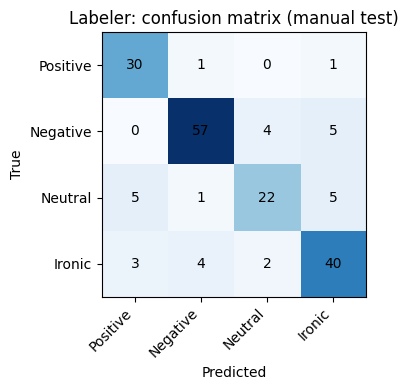

('labeler_model/tokenizer_config.json',
 'labeler_model/special_tokens_map.json',
 'labeler_model/vocab.txt',
 'labeler_model/added_tokens.json',
 'labeler_model/tokenizer.json')

In [ ]:
# [EVAL]
out = trainer.predict(ds_test)
y_true, y_pred = out.label_ids, out.predictions.argmax(-1)
results["labeler_test"] = {"accuracy": round(accuracy_score(y_true, y_pred), 4),
                           "macro_f1": round(f1_score(y_true, y_pred, average="macro", labels=list(range(len(LABELS)))), 4)}
print("Fine-tuned labeler on MANUAL TEST:", results["labeler_test"])
print(classification_report(y_true, y_pred, labels=list(range(len(LABELS))), target_names=LABELS, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(LABELS))))
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS, rotation=45, ha="right")
ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, cm[i, j], ha="center", va="center")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Labeler: confusion matrix (manual test)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_confusion_matrix_labeler.png", dpi=200); plt.show()

trainer.save_model("labeler_model"); tokenizer.save_pretrained("labeler_model")

## 7. Pseudo-label everything else
Every row that is **not** in your manual set is predicted. If the top probability is **>= THRESHOLD** the prediction becomes a pseudo-label; otherwise the row stays **unlabeled**.

In [ ]:
# [PREDICT]
pool = merged[~merged.id.isin(gold.id)].reset_index(drop=True)
print(f"Rows to pseudo-label: {len(pool):,}")

def predict_proba(texts, bs=64):
    model.to(device).eval()
    order = np.argsort([len(t) for t in texts])          # sort by length = faster batching
    probs = np.zeros((len(texts), len(LABELS)), dtype=np.float32)
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]
        enc = tokenizer([texts[j] for j in idx], padding=True, truncation=True,
                        max_length=MAX_LEN, return_tensors="pt").to(device)
        with torch.no_grad():
            probs[idx] = torch.softmax(model(**enc).logits, dim=-1).cpu().numpy()
    return probs

probs = predict_proba(pool.text.tolist())

Rows to pseudo-label: 39,682


Threshold = 0.9: kept 19,087 of 39,682 (48.1%); unlabeled 20,595

Pseudo-labels per class:


,count
label,
Positive,1577
Negative,12104
Neutral,740
Ironic,4666


Kept share per source:


,share_pseudo_labeled
source,
Bank,0.639
Sa7r,0.299
Telecom,0.660


Sanity check: original dataset label vs predicted label (kept rows only)


pred_label          Ironic  Negative  Neutral  Positive
source  orig_label                                     
Bank    NEG             26      6024      248         2
        NEU              5       253      286         0
        POS              9       129      119       273
Sa7r    تهكم          2599        31        1       112
        ليست تهكم     1986        44        6       915
Telecom Negative        40      5599       63         5
        Positive         1        24       17       270

How many rows each threshold would keep:


,threshold,share_kept
0,0.50,0.937
1,0.60,0.865
2,0.70,0.788
3,0.80,0.688
4,0.90,0.481
5,0.95,0.276


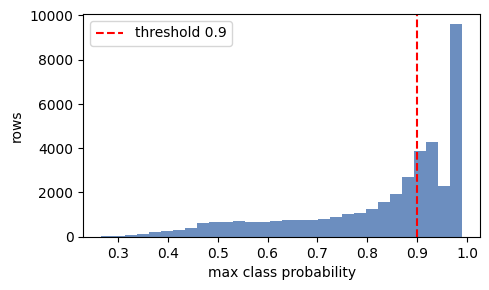

In [ ]:
pool["pred_label"] = [LABELS[i] for i in probs.argmax(1)]
pool["confidence"] = probs.max(1)
for j, l in enumerate(LABELS):
    pool[f"p_{l}"] = probs[:, j]

keep = pool["confidence"] >= THRESHOLD
pool["label"] = pool["pred_label"].where(keep)             # NaN when below threshold
pool["label_type"] = np.where(keep, "pseudo", "unlabeled")
pool["split"] = "pool"

print(f"Threshold = {THRESHOLD}: kept {keep.sum():,} of {len(pool):,} ({keep.mean():.1%}); unlabeled {(~keep).sum():,}")
print("\nPseudo-labels per class:")
display(pool.loc[keep, "label"].value_counts().reindex(LABELS).fillna(0).astype(int).to_frame("count"))
print("Kept share per source:")
display(pool.groupby("source")["label_type"].apply(lambda s: (s == "pseudo").mean()).round(3).to_frame("share_pseudo_labeled"))

print("Sanity check: original dataset label vs predicted label (kept rows only)")
display(pd.crosstab([pool.loc[keep, "source"], pool.loc[keep, "orig_label"]], pool.loc[keep, "pred_label"]))

sweep = pd.DataFrame({"threshold": [0.5, 0.6, 0.7, 0.8, 0.9, 0.95],
                      "share_kept": [(pool.confidence >= t).mean() for t in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]]}).round(3)
print("How many rows each threshold would keep:"); display(sweep)

plt.figure(figsize=(5, 3)); plt.hist(pool.confidence, bins=30, color="#6c8ebf")
plt.axvline(THRESHOLD, color="red", ls="--", label=f"threshold {THRESHOLD}")
plt.xlabel("max class probability"); plt.ylabel("rows"); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_confidence_hist.png", dpi=200); plt.show()

results["pseudo_labeled_rows"] = int(keep.sum())
results["unlabeled_rows"] = int((~keep).sum())

## 8. Export

In [ ]:
gold_out = gold.merge(merged[["id", "orig_label"]], on="id", how="left")
gold_out["label_type"] = "manual"
gold_out["confidence"] = np.nan
cols = ["id", "source", "text", "orig_label", "label", "label_type", "split", "confidence"]

final = pd.concat([gold_out[cols], pool[cols]], ignore_index=True).sort_values("id")
files_out = {
    "final_dataset_all.csv":    final,
    "manual_gold.csv":          final[final.label_type == "manual"],
    "pseudo_labeled.csv":       pool[pool.label_type == "pseudo"][cols + [f"p_{l}" for l in LABELS]],
    "unlabeled_remaining.csv":  pool[pool.label_type == "unlabeled"][cols + [f"p_{l}" for l in LABELS]],
}
for fname, df in files_out.items():
    df.to_csv(f"{OUT_DIR}/{fname}", index=False, encoding="utf-8-sig")
    print(f"{fname:28s} {len(df):>8,} rows")

stats = (final.assign(label=final.label.fillna("UNLABELED"))
              .pivot_table(index="label", columns="label_type", values="id", aggfunc="count", fill_value=0))
stats.to_csv(f"{OUT_DIR}/dataset_stats.csv")
print("\nFinal label distribution by type (use as the class-distribution table in the paper):")
display(stats)

import transformers, sklearn
results["versions"] = {"python": platform.python_version(), "torch": torch.__version__,
                       "transformers": transformers.__version__, "sklearn": sklearn.__version__}
results["config"] = {"max_len": MAX_LEN, "lr": LR, "batch": BATCH, "epochs": EPOCHS, "patience": PATIENCE,
                     "min_words": MIN_WORDS, "n_second_annotator": N_SECOND_ANNOTATOR}
with open(f"{OUT_DIR}/results_summary.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False, default=str)

zip_path = "semi_supervised_dataset.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for fn in sorted(os.listdir(OUT_DIR)):
        if fn.endswith((".csv", ".json", ".png")) and fn not in ("sample_meta_hidden.csv",):
            z.write(os.path.join(OUT_DIR, fn), fn)
print("\nZipped:", zip_path)
download(zip_path)
# To keep the labeler model: copy the "labeler_model" folder to Google Drive, it is not included in the zip (large).

final_dataset_all.csv          40,882 rows
manual_gold.csv                 1,200 rows
pseudo_labeled.csv             19,087 rows
unlabeled_remaining.csv        20,595 rows

Final label distribution by type (use as the class-distribution table in the paper):


label_type,manual,pseudo,unlabeled
label,,,
Ironic,328,4666,0
Negative,438,12104,0
Neutral,221,740,0
Positive,213,1577,0
UNLABELED,0,0,20595



Zipped: semi_supervised_dataset.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>